In [ ]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib import rc
import pandas as pd
import netCDF4
import xarray as xr
import numpy as np
from datetime import datetime
import time
from matplotlib import ticker
import matplotlib.colors as colors

In [3]:
path5 = '/Users/adrientirouvanziam/Desktop/WFIP3 Data/Barg_Ceil_Incomplete/barg.ceil.z01.c0.20240925.000000.nc'
dats5 = xr.open_dataset(path5)
path6 = '/Users/adrientirouvanziam/Desktop/WFIP3 Data/Barg_Ceil_Incomplete/barg.ceil.z01.c0.20240926.000000.nc'
dats6 = xr.open_dataset(path6)
path7 = '/Users/adrientirouvanziam/Desktop/WFIP3 Data/Barg_Ceil_Incomplete/barg.ceil.z01.c0.20240927.000000.nc'
dats7 = xr.open_dataset(path7)
path8 = '/Users/adrientirouvanziam/Desktop/WFIP3 Data/Barg_Ceil_Incomplete/barg.ceil.z01.c0.20240928.000000.nc'
dats8 = xr.open_dataset(path8)
path9 = '/Users/adrientirouvanziam/Desktop/WFIP3 Data/Barg_Ceil_Incomplete/barg.ceil.z01.c0.20240929.000000.nc'
dats9 = xr.open_dataset(path9)

In [6]:
bpd5 = dats5['Bs_profile_data']
bpd6 = dats6['Bs_profile_data']
bpd7 = dats7['Bs_profile_data']
bpd8 = dats8['Bs_profile_data']
bpd9 = dats9['Bs_profile_data']

In [8]:
bpd = np.concatenate((bpd5,bpd6,bpd7,bpd8,bpd9),axis=0)

In [10]:
awry5 = dats5.time
vec5 = awry5.values
awry6 = dats6.time
vec6 = awry6.values
awry7 = dats7.time
vec7 = awry7.values
awry8 = dats8.time
vec8 = awry8.values
awry9 = dats9.time
vec9 = awry9.values

In [11]:
lalnew5 = vec5[0]
galnew5 = datetime.fromtimestamp(lalnew5)
calnew5 = [pd.to_datetime(galnew5)]

lalnew6 = vec6[0]
galnew6 = datetime.fromtimestamp(lalnew6)
calnew6 = [pd.to_datetime(galnew6)]

lalnew7 = vec7[0]
galnew7 = datetime.fromtimestamp(lalnew7)
calnew7 = [pd.to_datetime(galnew7)]

lalnew8 = vec8[0]
galnew8 = datetime.fromtimestamp(lalnew8)
calnew8 = [pd.to_datetime(galnew8)]

lalnew9 = vec9[0]
galnew9 = datetime.fromtimestamp(lalnew9)
calnew9 = [pd.to_datetime(galnew9)]

In [12]:
for i in range(1,len(vec5)):
    lal5 = vec5[i]
    gal5 = datetime.fromtimestamp(lal5)
    cal5 = [pd.to_datetime(gal5)]
    calnew5 = np.concatenate((calnew5,cal5),axis=0)

for i in range(1,len(vec6)):
    lal6 = vec6[i]
    gal6 = datetime.fromtimestamp(lal6)
    cal6 = [pd.to_datetime(gal6)]
    calnew6 = np.concatenate((calnew6,cal6),axis=0)

for i in range(1,len(vec7)):
    lal7 = vec7[i]
    gal7 = datetime.fromtimestamp(lal7)
    cal7 = [pd.to_datetime(gal7)]
    calnew7 = np.concatenate((calnew7,cal7),axis=0)

for i in range(1,len(vec8)):
    lal8 = vec8[i]
    gal8 = datetime.fromtimestamp(lal8)
    cal8 = [pd.to_datetime(gal8)]
    calnew8 = np.concatenate((calnew8,cal8),axis=0)

for i in range(1,len(vec9)):
    lal9 = vec9[i]
    gal9 = datetime.fromtimestamp(lal9)
    cal9 = [pd.to_datetime(gal9)]
    calnew9 = np.concatenate((calnew9,cal9),axis=0)

In [13]:
np.shape(calnew5), np.shape(calnew6), np.shape(calnew7), np.shape(calnew8), np.shape(calnew9)

((4800,), (4804,), (4803,), (4800,), (4800,))

In [25]:
calnew = np.concatenate((calnew5,calnew6,calnew7,calnew8,calnew9),axis=0)
calnewv = np.reshape(calnew,(24007,1))

In [27]:
c5 = np.concatenate((calnewv,calnewv,calnewv,calnewv,calnewv),axis=1)
c25 = np.concatenate((c5,c5,c5,c5,c5),axis=1)
c75 = np.concatenate((c25,c25,c25),axis=1)
c225 = np.concatenate((c75,c75,c75),axis=1)
c450 = np.concatenate((c225,c225),axis=1)

In [28]:
h = dats5.range * 0.001

In [30]:
h5 = np.concatenate((h,h,h,h,h),axis=0)
h15 = np.concatenate((h5,h5,h5),axis=0)
h30 = np.concatenate((h15,h15),axis=0)
h60 = np.concatenate((h30,h30),axis=0)
h120 = np.concatenate((h60,h60),axis=0)
h240 = np.concatenate((h120,h120),axis=0)
h480 = np.concatenate((h240,h240),axis=0)
h960 = np.concatenate((h480,h480),axis=0)
h4800 = np.concatenate((h960,h960,h960,h960,h960),axis=0)
h24007 = np.concatenate((h4800,h4800,h4800,h4800,h4800,h5,h,h))
hbig = np.reshape(h24007,(24007,450))

In [107]:
bs = bpd * 0.00000001
logbs = np.log10(bs)

/var/folders/7c/3j2lw9753fj8nl6cdx7k0wg00000gq/T/ipykernel_42164/341202135.py:2: RuntimeWarning: divide by zero encountered in log10
  logbs = np.log10(bs)
/var/folders/7c/3j2lw9753fj8nl6cdx7k0wg00000gq/T/ipykernel_42164/341202135.py:2: RuntimeWarning: invalid value encountered in log10
  logbs = np.log10(bs)


In [108]:
cl5 = dats5.cloud_data
cl6 = dats6.cloud_data
cl7 = dats7.cloud_data
cl8 = dats8.cloud_data
cl9 = dats9.cloud_data
clb5 = cl5[0:4800,0] * 0.001
clb6 = cl6[0:4804,0] * 0.001
clb7 = cl7[0:4803,0] * 0.001
clb8 = cl8[0:4800,0] * 0.001
clb9 = cl9[0:4800,0] * 0.001
clbavg = np.ones(120)

In [109]:
clb = np.concatenate((clb5,clb6,clb7,clb8,clb9),axis=0)

In [110]:
for i in range(0,120):
    clbavg[i] = np.mean((clb[200*i:200*(i+1)])[clb[200*i:200*(i+1)]>0])

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [111]:
timavg = np.concatenate((calnewv[100:24100:200]),axis=0)

In [112]:
cbig = c450[800:22408,:]
hsmall = hbig[800:22408,:]
logbig = logbs[800:22408,:]
bsbig = bs[800:22408,:]

In [113]:
timbig = timavg[4:112]
clbbig = clbavg[4:112]

(0.0, 6.0)

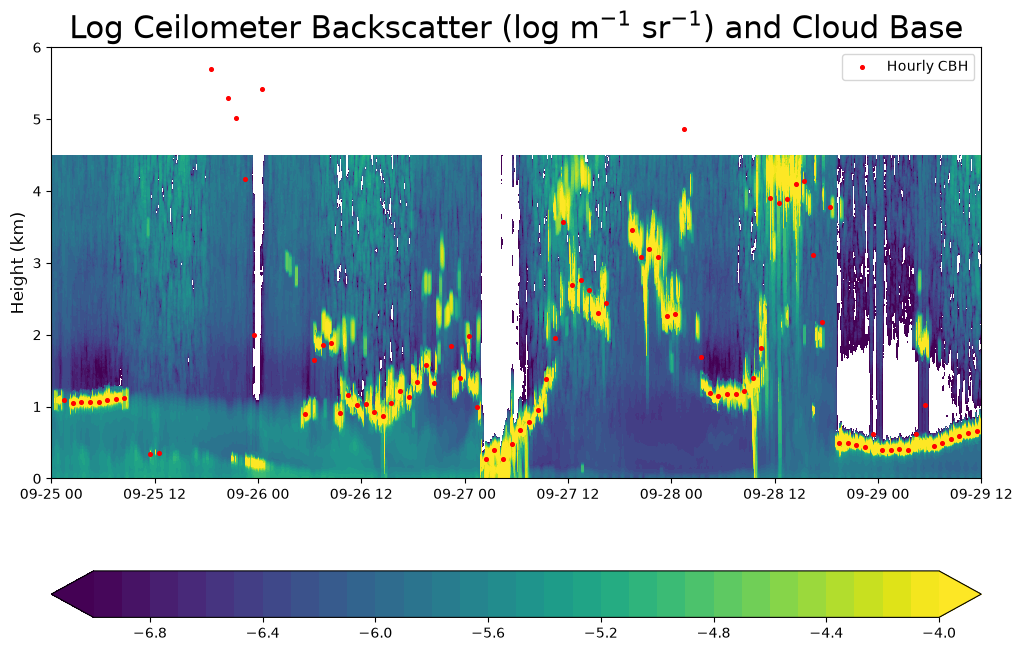

In [114]:
fig = plt.figure(figsize=(12,8))
plt.title('Log Ceilometer Backscatter (log m$^{-1}$ sr$^{-1}$) and Cloud Base',fontsize = 22)
#cf=plt.contourf(c450,hbig,logbs,np.arange(-7,-3.9,0.1),cmap='viridis',extend='both')
cf=plt.contourf(cbig,hsmall,logbig,np.arange(-7,-3.9,0.1),cmap='viridis',extend='both')
#cf=plt.contourf(cbig,hsmall,bsbig,locator=ticker.LogLocator(base=10.0, subs=(1.0,)),cmap='viridis',extend='both')
cbar=plt.colorbar(cf,orientation='horizontal')

#plt.scatter(timavg,clbavg,c='r',s=7,label='Hourly CBH')
plt.scatter(timbig,clbbig,c='r',s=7,label='Hourly CBH')

plt.legend(loc='upper right')
plt.ylabel('Height (km)',fontsize=12)
plt.ylim(0,6)